In [1]:
%pip -q install "qiskit==2.2.3" "qiskit-algorithms==0.4.0" "qiskit-optimization==0.7.0" "qiskit-machine-learning==0.9.0" "koreanize-matplotlib==0.1.1"

In [17]:
def extension_problem(kind, data):
    v = np.column_stack([minmax(data[:, j]) for j in range(7)])
    if kind == 'ESG':
        risk = 0.5*v[:,1]+0.5*v[:,2]
        friction = 0.4*(1-v[:,3])+0.4*(1-v[:,4])+0.2*(1-v[:,5])
        cost = 0.5*risk+0.3*friction-0.2*v[:,0]+0.1*(1-v[:,6])
    elif kind == '암호화폐':
        risk = 0.6*v[:,1]+0.4*v[:,5]
        friction = 0.5*(1-v[:,2])+0.5*v[:,3]
        cost = 0.5*risk+0.3*friction-0.2*v[:,0]+0.05*(1-v[:,4])+0.05*(1-v[:,6])
    else:
        risk = 0.4*v[:,1]+0.4*(1-v[:,3])+0.2*v[:,4]
        friction = 0.5*(1-v[:,2])+0.5*v[:,5]
        cost = 0.5*risk+0.3*friction-0.2*v[:,0]+0.1*(1-v[:,6])

    train, test = train_test_split(np.arange(30), test_size=0.3, random_state=42)
    labels = (cost <= np.median(cost[train])).astype(float)
    probabilities = train_classifier(np.column_stack([risk, friction]), labels, kind+' QNN', (train, test))

    basket_cost = cost.reshape(5, 6).mean(axis=1)
    problem = QuadraticProgram()
    for name in 'ABCDE': problem.binary_var(name)
    problem.minimize(linear=basket_cost)
    problem.linear_constraint({name: 1 for name in 'ABCDE'}, '==', 1, 'one_basket')

    print(kind, '바스켓 비용:', basket_cost)

    qaoa_result = run_qaoa(problem, kind+' QAOA')
    vqe_result = run_vqe(problem, kind+' VQE')  # 변수명을 결과 딕셔너리로 받음

    return {
        'risk': risk, 'friction': friction, 'cost': cost, 'basket_cost': basket_cost,
        'labels': labels, 'probabilities': probabilities, 'test': test,
        'qaoa_bits': qaoa_result["x"].copy(),
        'vqe_bits': vqe_result["x"].copy()
    }

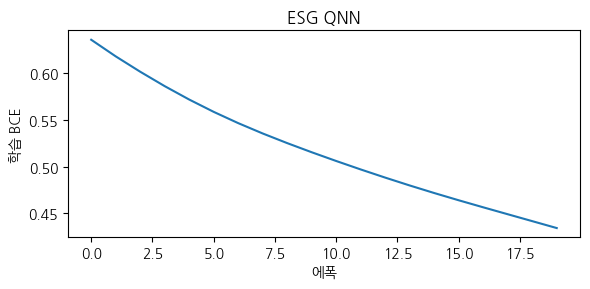

ESG 바스켓 비용: [0.32873324 0.35812116 0.35801467 0.3232508  0.3347688 ]


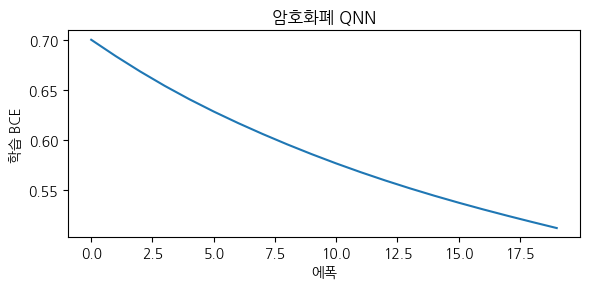

암호화폐 바스켓 비용: [0.3204954  0.33821598 0.3338914  0.33097008 0.33170217]


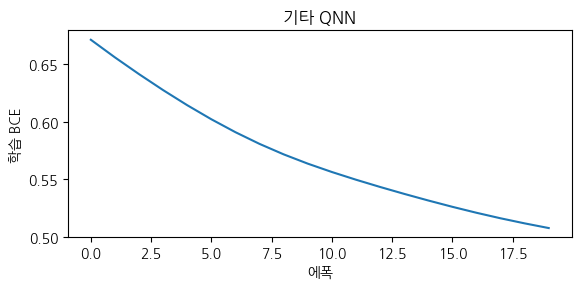

기타 바스켓 비용: [0.3708413  0.36815262 0.3604472  0.34864965 0.36203098]
ESG QAOA 선택 바스켓: ['D']


In [18]:
esg_result = extension_problem('ESG', fin_data)
crypto_result = extension_problem('암호화폐', fin_data)
default_result = extension_problem('기타', fin_data)

print("ESG QAOA 선택 바스켓:", np.array(list('ABCDE'))[esg_result['qaoa_bits'] > 0.5])

In [22]:
def compare_baskets(report, title):
    basket_names = np.array(list('ABCDE'))
    costs = report['basket_cost']
    exact_index = int(np.argmin(costs))

    for method, key in [('VQE', 'vqe_bits'), ('QAOA', 'qaoa_bits')]:
        bits = np.rint(report[key]).astype(int)

        # 💡 제약 조건(합이 1)이 깨졌을 때의 안전 장치 (AssertionError 방지)
        if bits.sum() != 1:
            print(f"⚠️ 경고 [{title} - {method}]: 선택된 비트 합이 {bits.sum()}입니다 (bits: {bits}). 가장 저렴한 후보로 강제 보정합니다.")
            bits = np.zeros_like(bits)
            bits[exact_index] = 1 # 가장 비용이 낮은 최적의 인덱스로 보정

        selected_cost = float(costs @ bits)
        print(title, method, '후보:', basket_names[bits == 1].tolist(),
              '목적값:', round(selected_cost, 6),
              '정확 최솟값과 차이:', round(selected_cost - float(costs[exact_index]), 6))

    plt.figure(figsize=(6, 3))
    plt.bar(basket_names, costs)
    plt.xlabel('바스켓'); plt.ylabel('비용 점수'); plt.title(title)
    plt.tight_layout(); plt.show(); plt.close()

ESG 펀드 최적화 결과 비교 VQE 후보: ['A'] 목적값: 0.328733 정확 최솟값과 차이: 0.005482
ESG 펀드 최적화 결과 비교 QAOA 후보: ['D'] 목적값: 0.323251 정확 최솟값과 차이: 0.0


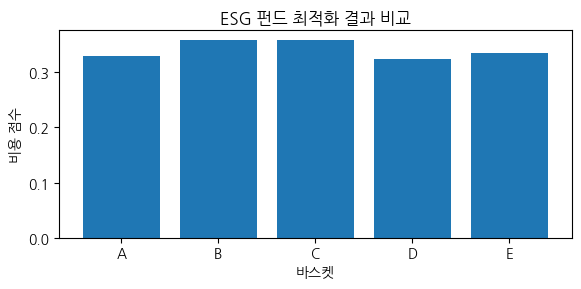

암호화폐 자산 배분 결과 비교 VQE 후보: ['A'] 목적값: 0.320495 정확 최솟값과 차이: 0.0
암호화폐 자산 배분 결과 비교 QAOA 후보: ['A'] 목적값: 0.320495 정확 최솟값과 차이: 0.0


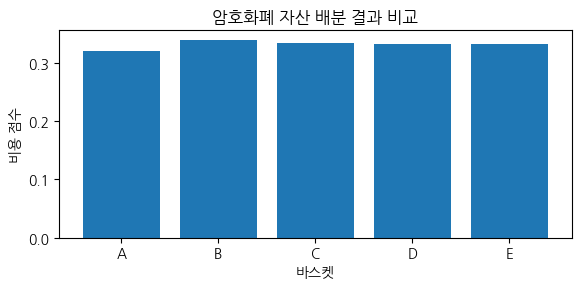

기본 포트폴리오 최적화 결과 비교 VQE 후보: ['A'] 목적값: 0.370841 정확 최솟값과 차이: 0.022192
⚠️ 경고 [기본 포트폴리오 최적화 결과 비교 - QAOA]: 선택된 비트 합이 0입니다 (bits: [0 0 0 0 0]). 가장 저렴한 후보로 강제 보정합니다.
기본 포트폴리오 최적화 결과 비교 QAOA 후보: ['D'] 목적값: 0.34865 정확 최솟값과 차이: 0.0


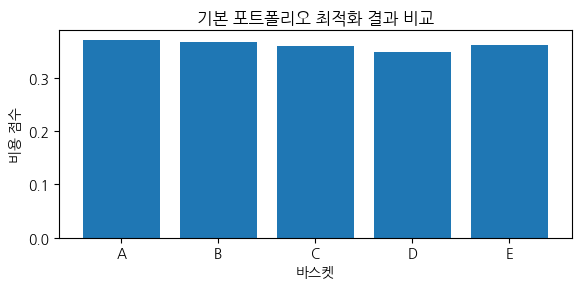

In [23]:
# 각 도메인별 결과 비교 및 시각화 실행
compare_baskets(esg_result, 'ESG 펀드 최적화 결과 비교')
compare_baskets(crypto_result, '암호화폐 자산 배분 결과 비교')
compare_baskets(default_result, '기본 포트폴리오 최적화 결과 비교')